# Load the dataset

In [4]:
import numpy as np
import pandas as pd

In [7]:
df = pd.read_parquet('ieee_fraud_detection.parquet' , engine='pyarrow')

In [8]:
df.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V312,V313,V314,V315,V316,V317,V318,V319,V320,V321
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,0.0,0.0,0.0,0.0,0.0,117.0,0.0,0.0,0.0,0.0
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,135.0,0.0,0.0,0.0,50.0,1404.0,790.0,0.0,0.0,0.0
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [9]:
df.set_index('TransactionID', inplace=True)

# Structure of Dataset

In [10]:
df.shape

(590528, 201)

In [11]:
df.info()

<class 'pandas.DataFrame'>
Index: 590528 entries, 2987000 to 3577539
Columns: 201 entries, isFraud to V321
dtypes: float32(193), int32(3), str(5)
memory usage: 478.4 MB


In [12]:
df.describe()

,isFraud,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,C1,...,V312,V313,V314,V315,V316,V317,V318,V319,V320,V321
count,590528.000000,5.905280e+05,590528.000000,590528.000000,581595.000000,588963.000000,586270.000000,524833.000000,524833.000000,590528.000000,...,590517.000000,589264.000000,589264.000000,589264.000000,590517.000000,590517.000000,590517.000000,590517.000000,590517.000000,590517.000000
mean,0.034991,7.372219e+06,135.028992,9898.731525,362.554474,153.194458,199.279602,290.733826,86.800682,14.092257,...,39.174637,21.351727,43.319691,26.807297,109.820587,247.611343,162.156403,18.372820,42.073914,28.327110
std,0.183756,4.617198e+06,239.164536,4901.178720,157.793457,11.335713,41.244003,101.741173,2.690372,133.570053,...,172.129868,95.903511,173.619995,116.853882,2270.054199,3980.079834,2793.369629,332.307922,473.503693,382.056702
min,0.000000,8.640000e+04,0.251000,1000.000000,100.000000,100.000000,100.000000,100.000000,10.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,3.027022e+06,43.342999,6019.000000,214.000000,150.000000,166.000000,204.000000,87.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,7.306314e+06,68.793999,9678.000000,361.000000,150.000000,226.000000,299.000000,87.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,1.124610e+07,125.000000,14184.000000,512.000000,150.000000,226.000000,330.000000,87.000000,3.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.581113e+07,31937.390625,18396.000000,600.000000,231.000000,237.000000,540.000000,102.000000,4685.000000,...,55125.000000,4817.470215,7519.870117,4817.470215,93736.000000,134021.000000,98476.000000,104060.000000,104060.000000,104060.000000


In [14]:
df.dtypes

isFraud             int32
TransactionDT       int32
TransactionAmt    float32
ProductCD             str
card1               int32
                   ...   
V317              float32
V318              float32
V319              float32
V320              float32
V321              float32
Length: 201, dtype: object

In [15]:
df.dtypes.value_counts()

float32    193
str          5
int32        3
Name: count, dtype: int64

# Data cleanign and preprocessing

In [16]:
 # Total number of rows
total_rows = df.shape[0]
total_rows

590528

In [24]:
def check_missing(df, dtype='object'):
    # Total number of rows
    total_rows = df.shape[0]

    # Check missing values and their percentage for specified dtype
    missing_ = df.select_dtypes(include=dtype).isnull().sum()
    missing_percent = (missing_ / total_rows) * 100

    # Combine into a DataFrame for better readability
    missing_summary = pd.DataFrame({
        'Missing Values': missing_,
        'Missing Percentage (%)': missing_percent.round(2)
    })

    # Filter out columns without missing values
    missing_summary = missing_summary[missing_summary['Missing Values'] > 0]

    # Sort by missing percentage
    return missing_summary.sort_values(by='Missing Percentage (%)', ascending=False)

In [25]:
# For numeric types
check_missing(df, dtype=['float32', 'int32'])

,Missing Values,Missing Percentage (%)
V52,168957,28.61
V51,168957,28.61
V37,168957,28.61
V38,168957,28.61
V39,168957,28.61
...,...,...
V317,11,0.00
V318,11,0.00
V319,11,0.00
V320,11,0.00


In [26]:
# For categorical
check_missing(df, dtype='object')

C:\Users\23shr\AppData\Local\Temp\ipykernel_15244\627231578.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  missing_ = df.select_dtypes(include=dtype).isnull().sum()


,Missing Values,Missing Percentage (%)
M6,169348,28.68
P_emaildomain,94454,15.99
card6,1571,0.27
card4,1577,0.27


In [27]:
# Fill numeric columns with median
num_cols = df.select_dtypes(include=['number']).columns
for col in num_cols:
  median = df[col].median()
  df.fillna({col:median}, inplace=True)

In [28]:
# Fill categorical columns with most frequent value (mode)
cat_cols = df.select_dtypes(include=['object', 'category']).columns
for col in cat_cols:
  mode = df[col].mode(dropna=True)
  if not mode.empty:
    df.fillna({col:mode[0]}, inplace=True)

C:\Users\23shr\AppData\Local\Temp\ipykernel_15244\3932126484.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns


In [29]:
df.isnull().sum()

isFraud           0
TransactionDT     0
TransactionAmt    0
ProductCD         0
card1             0
                 ..
V317              0
V318              0
V319              0
V320              0
V321              0
Length: 201, dtype: int64

# Encoding categorical features

In [30]:
# Select categorical columns
cat_cols = df.select_dtypes(include='object').columns

# Count unique values in each categorical column
cardinality = df[cat_cols].nunique().sort_values(ascending=False)

# Display the result
print(cardinality)

P_emaildomain    59
ProductCD         5
card4             4
card6             4
M6                2
dtype: int64


C:\Users\23shr\AppData\Local\Temp\ipykernel_15244\510723729.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns


In [31]:
from sklearn.preprocessing import LabelEncoder

# Label Encoding for high-cardinality feature
le = LabelEncoder()
df['P_emaildomain'] = le.fit_transform(df['P_emaildomain'])

# One-Hot Encoding for low-cardinality features
df = pd.get_dummies(df, columns=['ProductCD', 'card4', 'card6', 'M6'], drop_first=True)

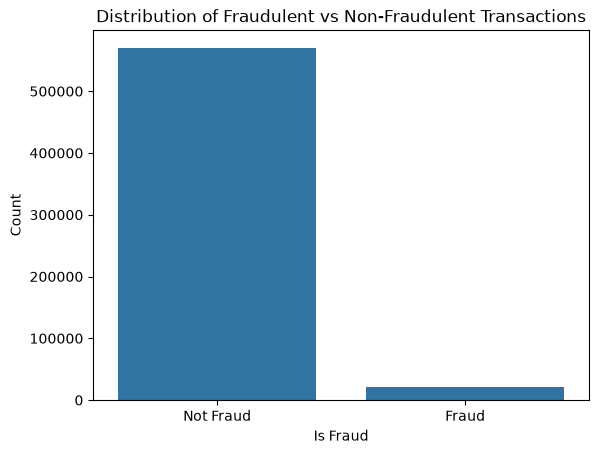

isFraud
0    96.500928
1     3.499072
Name: proportion, dtype: float64


In [32]:
# Visualize class imbalance
import seaborn as sns
import matplotlib.pyplot as plt

# Plot the class distribution
sns.countplot(x='isFraud', data=df)
plt.title('Distribution of Fraudulent vs Non-Fraudulent Transactions')
plt.xlabel('Is Fraud')
plt.ylabel('Count')
plt.xticks([0, 1], ['Not Fraud', 'Fraud'])
plt.show()

# Print percentage distribution
fraud_rate = df['isFraud'].value_counts(normalize=True) * 100
print(fraud_rate)

# Model training and evaluation

1. prepare

In [33]:
# Separate features and target
X = df.drop(columns=['isFraud'])
y = df['isFraud']

In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42
)

In [39]:
# Import Required Libraries
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import xgboost
from xgboost import XGBClassifier

In [40]:
classifier = XGBClassifier(eval_metric='logloss', random_state=42)

In [38]:
import sys
!{sys.executable} -m pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
    --------------------------------------- 1.0/48.9 MB 4.2 MB/s eta 0:00:12
   -- ------------------------------------- 2.9/48.9 MB 6.1 MB/s eta 0:00:08
   -- ------------------------------------- 3.7/48.9 MB 5.4 MB/s eta 0:00:09
   ---- ----------------------------------- 5.2/48.9 MB 5.9 MB/s eta 0:00:08
   ---- ----------------------------------- 5.8/48.9 MB 5.2 MB/s eta 0:00:09
   ----- ---------------------------------- 6.8/48.9 MB 5.1 MB/s eta 0:00:09
   ------ --------------------------------- 7.9/48.9 MB 5.1 MB/s eta 0:00:09
   ------ --------------------------------- 8.4/48.9 MB 4.8 MB/s eta 0:00:09
   ------- -------------------------------- 9.7/48.9 MB 5.0 MB/s eta 0:00:08
   -------- ------------------------------- 10.5/48.9 MB 4.8 MB/s eta 0:00:09
   -------- ------------------------------- 11.0/48.9 MB 4.9 MB/s eta 0:00:08
   --------

In [41]:
# Create pipeline
pipeline = ImbPipeline(steps=[
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('classifier', classifier)
])

In [42]:
pipeline.fit(X_train, y_train)

,steps,"[('scaler', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](207,)","['TransactionDT','TransactionAmt','card1',...,'card6_debit', 'card6_debit or credit','M6_T']"
n_features_in_,int,207
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [43]:
y_pred = pipeline.predict(X_test)

#3 Evaluate the model performance

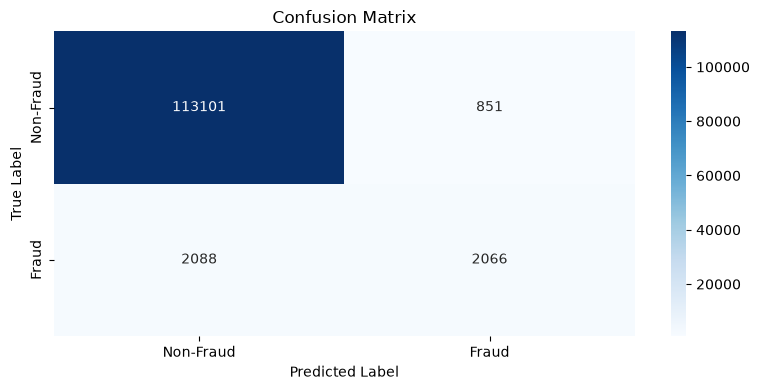

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

# Confusion matrix values from your result
cm = confusion_matrix(y_test, y_pred)

# Labels for display
labels = ["Non-Fraud", "Fraud"]

# Plot the confusion matrix
plt.figure(figsize=(8, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


In [45]:
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.99      0.99    113952
           1       0.71      0.50      0.58      4154

    accuracy                           0.98    118106
   macro avg       0.85      0.74      0.79    118106
weighted avg       0.97      0.98      0.97    118106

